# Numerical Coursework

## Dataset Description
The Real-Time Currency Prices for Sri Lanka dataset contains financial and economic data related to currency exchange rates and market prices. It can be used for regression to predict future currency values and for clustering to group currencies or time periods with similar market behavior. The dataset is valuable for analyzing currency trends, forecasting exchange rates, and discovering hidden patterns in financial data.

# Section 1:Import Libraries

In [1]:
import pandas as pd              
import numpy as np              
import matplotlib.pyplot as plt   
import seaborn as sns            

from sklearn.model_selection import train_test_split          
from sklearn.linear_model import LinearRegression            
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

## Section 2: Load the Dataset
We load the CSV file into a Pandas DataFrame

In [2]:
df=pd.read_csv('Realtime_Currency_Prices.csv')
print(f"   → Rows   : {df.shape[0]:,}")
print(f"   → Columns: {df.shape[1]}")

   → Rows   : 10,252
   → Columns: 82


## Section 3: Data Understanding
Before cleaning the data,we understand what the Data looks like

### 3.1   Preview first 5 rows


In [3]:
print('First 5 rows of the dataset')
df.head()

First 5 rows of the dataset


,ISO3,country,adm1_name,adm2_name,mkt_name,lat,lon,geo_id,DATES,year,...,l_wage_non_qualified_labour_non_agricultural,c_wage_non_qualified_labour_non_agricultural,inflation_wage_non_qualified_labour_non_agricultural,trust_wage_non_qualified_labour_non_agricultural,o_wage_qualified_labour,h_wage_qualified_labour,l_wage_qualified_labour,c_wage_qualified_labour,inflation_wage_qualified_labour,trust_wage_qualified_labour
0,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-01-01,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-02-01,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-03-01,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-04-01,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,LKA,Sri Lanka,Eastern,Ampara,Ampara,7.28,81.67,gid_72800000816700000,2007-05-01,2007,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 3.2   Shape of the dataset
df.shape() tells us the size of the dataset


In [4]:
print('Size of the dataset')
df.shape

Size of the dataset


(10252, 82)

### 3.3  Data types
Here,we will check what type of data each column includes

In [5]:
print('Data types:')
print(df.dtypes)

Data types:
ISO3                                   str
country                                str
adm1_name                              str
adm2_name                              str
mkt_name                               str
                                    ...   
h_wage_qualified_labour            float64
l_wage_qualified_labour            float64
c_wage_qualified_labour            float64
inflation_wage_qualified_labour    float64
trust_wage_qualified_labour        float64
Length: 82, dtype: object


### 3.4 Missing Values
Now,we will check how many missing values exist in each column.

In [6]:
df.isnull().sum()

ISO3                                   0
country                                0
adm1_name                              0
adm2_name                              0
mkt_name                               0
                                   ...  
h_wage_qualified_labour            10252
l_wage_qualified_labour            10252
c_wage_qualified_labour            10252
inflation_wage_qualified_labour    10252
trust_wage_qualified_labour        10252
Length: 82, dtype: int64

In [7]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print(missing_df.to_string())


                                                      Missing Count  Missing %
batteries                                                     10252      100.0
charcoal                                                      10252      100.0
candles                                                       10252      100.0
l_wage_non_qualified_labour                                   10252      100.0
trust_firewood                                                10252      100.0
firewood                                                      10252      100.0
milling_cost_sorghum                                          10252      100.0
soap                                                          10252      100.0
wage_non_qualified_labour                                     10252      100.0
wage_non_qualified_labour_non_agricultural                    10252      100.0
wage_qualified_labour                                         10252      100.0
o_batteries                                         

### 3.5 Statistical Summary
df.describe() gives us key statistics for every numerical column.

In [8]:
print('Statistical Summary:')
df.describe()

Statistical Summary:


,lat,lon,year,month,batteries,candles,charcoal,exchange_rate_unofficial,firewood,milling_cost_sorghum,...,l_wage_non_qualified_labour_non_agricultural,c_wage_non_qualified_labour_non_agricultural,inflation_wage_non_qualified_labour_non_agricultural,trust_wage_non_qualified_labour_non_agricultural,o_wage_qualified_labour,h_wage_qualified_labour,l_wage_qualified_labour,c_wage_qualified_labour,inflation_wage_qualified_labour,trust_wage_qualified_labour
count,10019.000000,10019.000000,10252.000000,10252.000000,0.0,0.0,0.0,10252.000000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,7.474419,80.546279,2016.214592,6.424893,NaN,NaN,NaN,179.607897,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.928279,0.521972,5.608847,3.458651,NaN,NaN,NaN,78.425473,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,5.950000,79.830000,2007.000000,1.000000,NaN,NaN,NaN,107.650000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,6.910000,80.010000,2011.000000,3.000000,NaN,NaN,NaN,114.900000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,7.230000,80.520000,2016.000000,6.000000,NaN,NaN,NaN,145.800000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,8.040000,80.990000,2021.000000,9.000000,NaN,NaN,NaN,198.470000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,9.660000,81.700000,2026.000000,12.000000,NaN,NaN,NaN,366.880000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# Section 4: Data Cleaning

Real world datasets contain:
Missing values,
Invalid values,
Duplicate values and
Irrelevant columns

We clean all of these issues in this section before doing any analysis

### 4.1 Drop columns

In [9]:
df = df.dropna(axis=1, how='all').copy()
print(f"Columns remaining after dropping fully-null columns: {df.shape[1]}")

Columns remaining after dropping fully-null columns: 18


### 4.2 Remove unnecessary columns

geo_id and ISO3/country are identifiers that add no analytical value(only one country-Sri Lanka)

In [10]:
df.drop(
    columns=[
        'geo_id',
        'ISO3',
        'country',
        'lat',
        'lon',
        'currency',
    ],
    errors='ignore',
    inplace=True
)

### 4.3 Handle missing values

In [11]:
df['inflation_exchange_rate_unofficial'] = (
    df['inflation_exchange_rate_unofficial']
    .fillna(df['inflation_exchange_rate_unofficial'].median())
)

### 4.4 Remove Duplicate Rows

In [12]:
df.drop_duplicates(inplace=True)

### 4.5 Convert Date Column

In [13]:
df['DATES'] = pd.to_datetime(df['DATES'])
print(f"DATES dtype : {df['DATES'].dtype}")
print(f"Date range  : {df['DATES'].min().date()} → {df['DATES'].max().date()}")

DATES dtype : datetime64[us]
Date range  : 2007-01-01 → 2026-05-01


### 4.6 Check for Invalid values


In [14]:
invalid_found = False

for col in df.select_dtypes(include=['object', 'string']).columns:
    if df[col].astype(str).str.contains(r'[#*@$%^&]', regex=True, na=False).any():
        print(f"Invalid symbols found in {col}")
        invalid_found = True

if not invalid_found:
    print("No invalid symbols found")

No invalid symbols found


### We will do a final summary check

In [15]:
print("Remaining Missing Values:")
print(df.isnull().sum().sum())

print("\nText Columns:")
print(df.select_dtypes(include=['object', 'string']).columns)

print("\nDataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

Remaining Missing Values:
0

Text Columns:
Index(['adm1_name', 'adm2_name', 'mkt_name'], dtype='str')

Dataset Shape:
(10252, 12)

Data Types:
adm1_name                                        str
adm2_name                                        str
mkt_name                                         str
DATES                                 datetime64[us]
year                                           int64
month                                          int64
exchange_rate_unofficial                     float64
o_exchange_rate_unofficial                   float64
h_exchange_rate_unofficial                   float64
l_exchange_rate_unofficial                   float64
c_exchange_rate_unofficial                   float64
inflation_exchange_rate_unofficial           float64
dtype: object


## Cleaned dataset summary

In [16]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Shape: (10252, 12)
Missing values: 0
Duplicate rows: 0


# Section 5:Explotary Data Analysis

### 5.1 Histogram
See how exchange rate values are spread

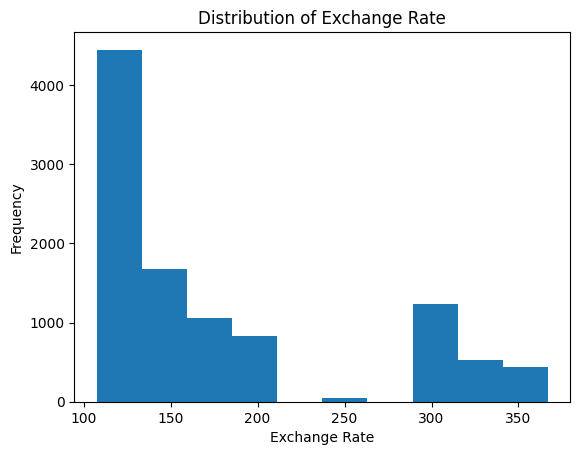

In [17]:
import matplotlib.pyplot as plt


plt.hist(df['exchange_rate_unofficial'])
plt.title("Distribution of Exchange Rate")
plt.xlabel("Exchange Rate")
plt.ylabel("Frequency")
plt.show()

The histogram shows how exchange rates are distributed. Most values are concentrated within a certain range, indicating consistency over time.

### 5.2 Line Chart
See how exchange rate changes over years

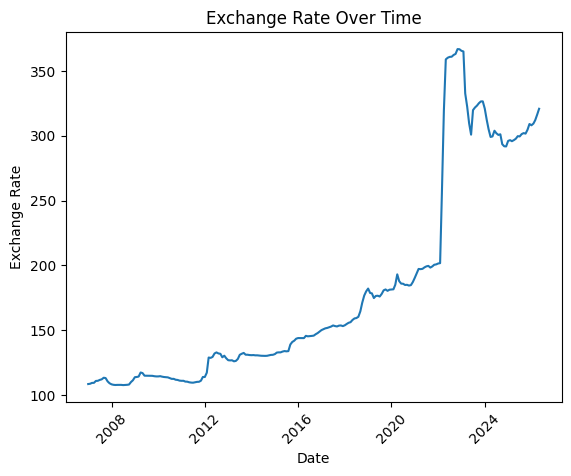

In [18]:
df_sorted = df.sort_values('DATES')
plt.plot(df_sorted['DATES'], df_sorted['exchange_rate_unofficial'])
plt.xlabel("Date")
plt.ylabel("Exchange Rate")
plt.title("Exchange Rate Over Time")
plt.xticks(rotation=45)
plt.show()

The line chart shows the trend of exchange rates over time. It helps identify increases or decreases across the years.

### 5.3 Boxplot
Check if there are extreme values

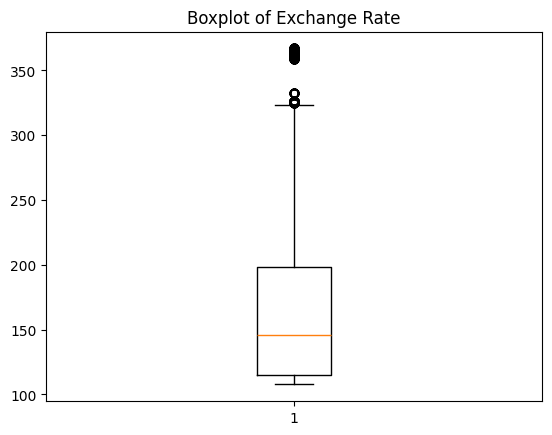

In [19]:
plt.boxplot(df['exchange_rate_unofficial'])
plt.title("Boxplot of Exchange Rate")
plt.show()

The boxplot highlights the spread and presence of outliers in the exchange rate data.

### 5.4 Correlation Heatmap
Check relationships between numeric columns

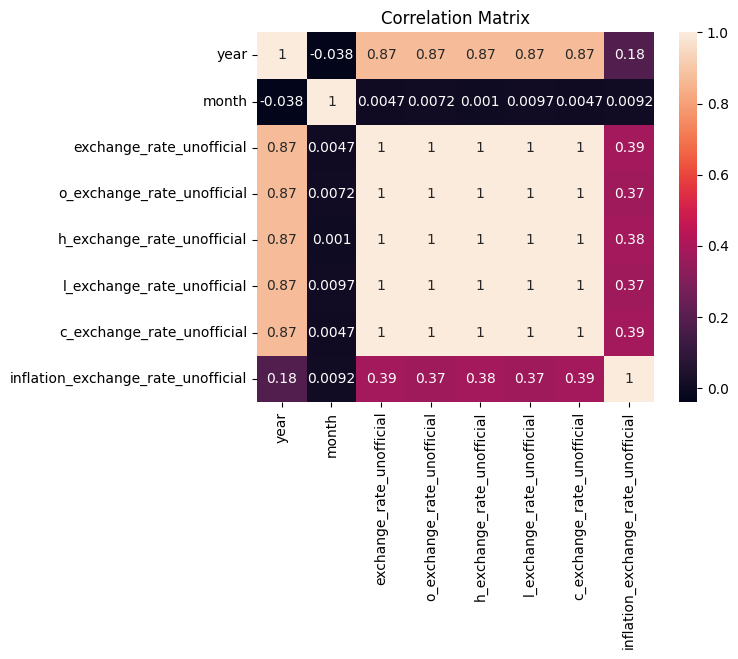

In [20]:
import seaborn as sns

corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True)
plt.title("Correlation Matrix")
plt.show()

The heatmap shows the relationship between variables. A higher value indicates stronger correlation.

### 5.5 Bar Chart
Compare average exchange rate across different markets.

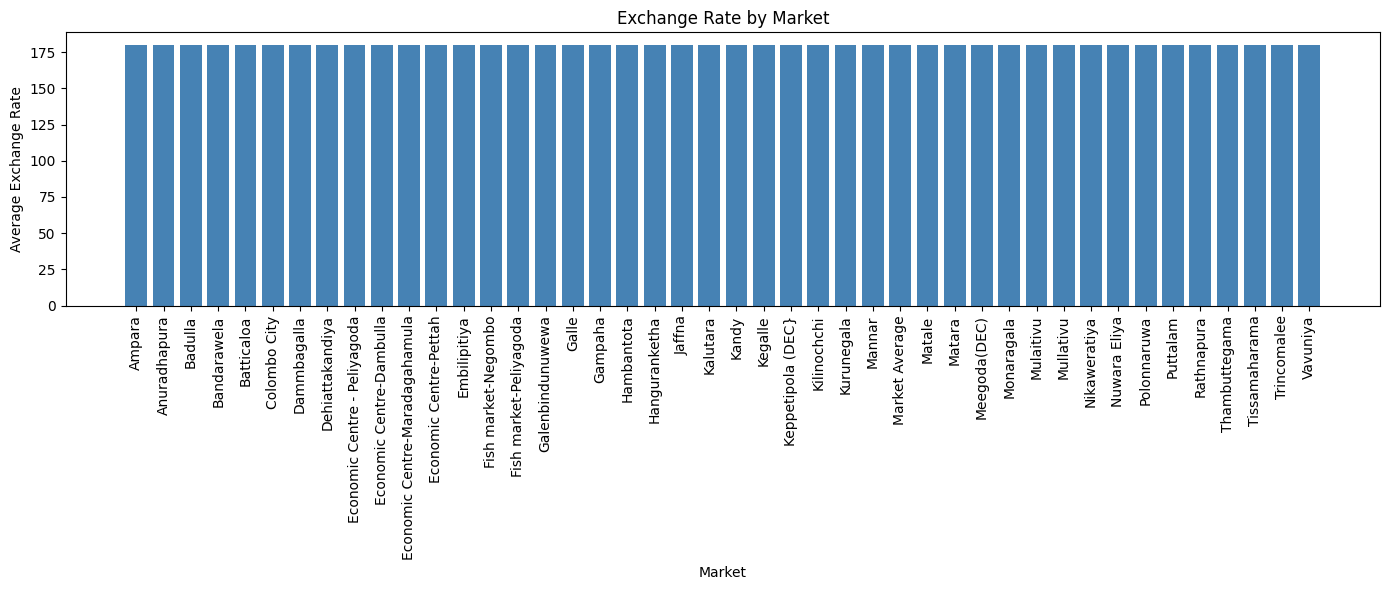

In [21]:
avg_rate = df.groupby('mkt_name')['exchange_rate_unofficial'].mean().dropna().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
plt.bar(avg_rate.index, avg_rate.values, color='steelblue')
plt.title('Exchange Rate by Market')
plt.xlabel('Market')
plt.ylabel('Average Exchange Rate')
plt.xticks(ticks=range(len(avg_rate)), labels=avg_rate.index, rotation=90)  # fix here
plt.tight_layout()
plt.show()

Sri Lanka had a fairly uniform unofficial exchange rate across all markets during most periods. 

# Section 6 Hypothesis Testing
## 6.1 T-Test
Compare two markets

In [22]:
from scipy import stats

western = df[df['adm1_name'] == 'Western']['exchange_rate_unofficial']
central = df[df['adm1_name'] == 'Central']['exchange_rate_unofficial']

t_stat, p_value = stats.ttest_ind(western, central)

print(f"T-Statistic: {t_stat:.4f}")
print(f"P-Value: {p_value:.4f}")

if p_value < 0.05:
    print("Result: Reject Null Hypothesis - Significant difference between provinces")
else:
    print("Result: Accept Null Hypothesis - No significant difference between provinces")

T-Statistic: 0.0000
P-Value: 1.0000
Result: Accept Null Hypothesis - No significant difference between provinces


This indicates no statistically significant difference between the two markets. This suggests that the unofficial exchange rate was uniformly consistent across all markets in Sri Lanka throughout the dataset period.

## 6.2 Paired T-Test
Opening vs Closing Exchange Rate


In [23]:
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(
    df['o_exchange_rate_unofficial'],
    df['c_exchange_rate_unofficial']
)

print("P-value:", p_value)

P-value: 1.3488638836586948e-12


The paired t-test was used to compare the opening and closing exchange rates. The p-value determines whether a statistically significant difference exists between the two rates.

# Section 7 Encoding categorical variables

### 7.1 Encode Categorical Variables


Categorical variables were converted into numerical form using Label Encoding.

In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in ['adm1_name', 'adm2_name', 'mkt_name']:
    df[col] = le.fit_transform(df[col])

# Section 8 Removing Date variable

In [25]:
df.drop(columns=['DATES'], errors='ignore', inplace=True)

print("DATES column removed successfully.")

DATES column removed successfully.


# Section 9 Linear Regression

In [26]:
X = df[['adm1_name', 'adm2_name', 'mkt_name', 'year', 'month']]

y = df['exchange_rate_unofficial']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

## 9.1 Model Evaluation

In [27]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("R² Score:", r2)

Mean Absolute Error (MAE): 31.065030164660055
Mean Squared Error (MSE): 1475.058025857378
R² Score: 0.7624685539810787


## 9.2 Model Visualisation

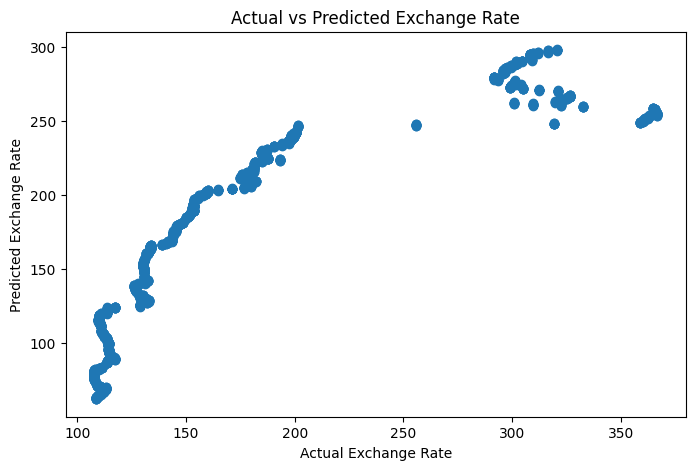

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Exchange Rate")
plt.ylabel("Predicted Exchange Rate")
plt.title("Actual vs Predicted Exchange Rate")

plt.show()

# Section 10 K-Means Clustering

In [29]:
X_cluster = df[
    [
        'exchange_rate_unofficial',
        'o_exchange_rate_unofficial',
        'h_exchange_rate_unofficial',
        'l_exchange_rate_unofficial',
        'c_exchange_rate_unofficial'
    ]
]

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_cluster)
print(df['Cluster'].value_counts())


Cluster
0    5324
2    2728
1    2200
Name: count, dtype: int64


## 10.1 Model Visualisation

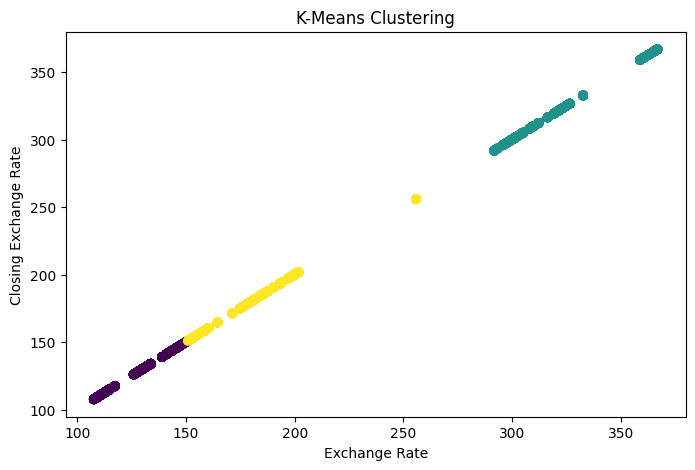

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.scatter(
    df['exchange_rate_unofficial'],
    df['c_exchange_rate_unofficial'],
    c=df['Cluster']
)

plt.xlabel('Exchange Rate')
plt.ylabel('Closing Exchange Rate')
plt.title('K-Means Clustering')

plt.show()

# Conclusion